## WellCo EDA
### Exploratory Data Analysis for churn + uplift assignment.

In [20]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys

plt.style.use("default")
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"


### 1. Load raw tables

In [21]:

web_path = DATA_RAW / "web_visits.csv"
app_path = DATA_RAW / "app_usage.csv"
claims_path = DATA_RAW / "claims.csv"
labels_path = DATA_RAW / "churn_labels.csv"

web = pd.read_csv(web_path)
app = pd.read_csv(app_path)
claims = pd.read_csv(claims_path)
labels = pd.read_csv(labels_path)

web["timestamp"] = pd.to_datetime(web["timestamp"], utc=True, errors="coerce")
app["timestamp"] = pd.to_datetime(app["timestamp"], utc=True, errors="coerce")
claims["diagnosis_date"] = pd.to_datetime(claims["diagnosis_date"], errors="coerce")
labels["signup_date"] = pd.to_datetime(labels["signup_date"], errors="coerce")

web.head(), app.head(), claims.head(), labels.head()


(   member_id                                url                title  \
 0          1  https://health.wellco/chronic/859  Diabetes management   
 1          1       https://portal.site/tech/328       Gadget roundup   
 2          1    https://health.wellco/heart/792  Hypertension basics   
 3          2     https://example.com/gaming/674         Game reviews   
 4          2   https://living.better/stress/325     Stress reduction   
 
                             description                 timestamp  
 0      Blood sugar and glycemic control 2025-07-02 22:38:22+00:00  
 1          Smartphones and laptops news 2025-07-02 11:30:47+00:00  
 2  Blood pressure and lifestyle changes 2025-07-14 00:38:39+00:00  
 3             Strategy tips and updates 2025-07-07 02:56:06+00:00  
 4              Mindfulness and wellness 2025-07-02 15:53:38+00:00  ,
    member_id event_type                 timestamp
 0          1    session 2025-07-13 08:43:37+00:00
 1          1    session 2025-07-14 15:28:5

### 2. Basic shapes and missingness


In [22]:
for name, df in [("web", web), ("app", app), ("claims", claims), ("labels", labels)]:
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print(df.dtypes)
    print("missing (%):")
    print(df.isna().mean().round(3))
    print()



--- web ---
shape: (259340, 5)
member_id                    int64
url                         object
title                       object
description                 object
timestamp      datetime64[ns, UTC]
dtype: object
missing (%):
member_id      0.0
url            0.0
title          0.0
description    0.0
timestamp      0.0
dtype: float64

--- app ---
shape: (97789, 3)
member_id                   int64
event_type                 object
timestamp     datetime64[ns, UTC]
dtype: object
missing (%):
member_id     0.0
event_type    0.0
timestamp     0.0
dtype: float64

--- claims ---
shape: (64576, 3)
member_id                  int64
icd_code                  object
diagnosis_date    datetime64[ns]
dtype: object
missing (%):
member_id         0.0
icd_code          0.0
diagnosis_date    0.0
dtype: float64

--- labels ---
shape: (10000, 4)
member_id               int64
signup_date    datetime64[ns]
churn                   int64
outreach                int64
dtype: object
missing (%):
member

### 3. Churn and outreach overview


Churn rate: 0.202
Outreach rate: 0.398

Churn by outreach:
churn         0      1
outreach              
0         0.793  0.207
1         0.806  0.194


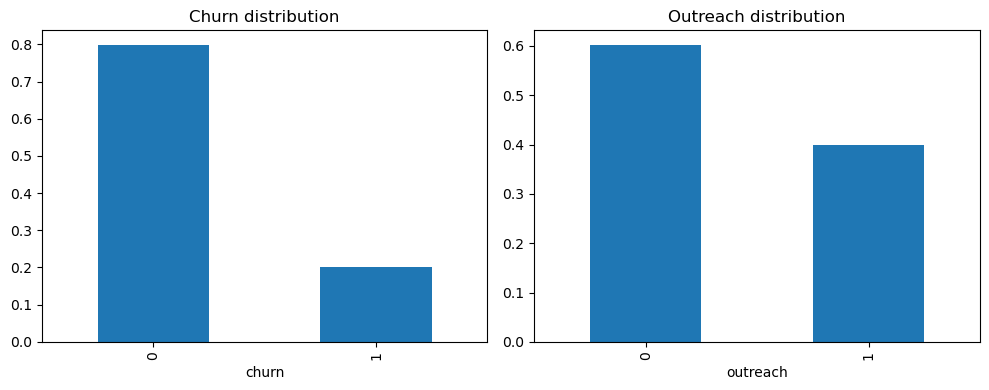

In [23]:
labels["churn"] = labels["churn"].astype("int64")
labels["outreach"] = labels["outreach"].astype("int64")

print("Churn rate:", labels["churn"].mean().round(3))
print("Outreach rate:", labels["outreach"].mean().round(3))

print("\nChurn by outreach:")
ct = pd.crosstab(labels["outreach"], labels["churn"], normalize="index")
print(ct.round(3))

# Simple bar plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

labels["churn"].value_counts(normalize=True).sort_index().plot(
    kind="bar", ax=axes[0], title="Churn distribution"
)
axes[0].set_xlabel("churn")

labels["outreach"].value_counts(normalize=True).sort_index().plot(
    kind="bar", ax=axes[1], title="Outreach distribution"
)
axes[1].set_xlabel("outreach")

plt.tight_layout()
plt.show()


### 4. Time coverage (observation window)


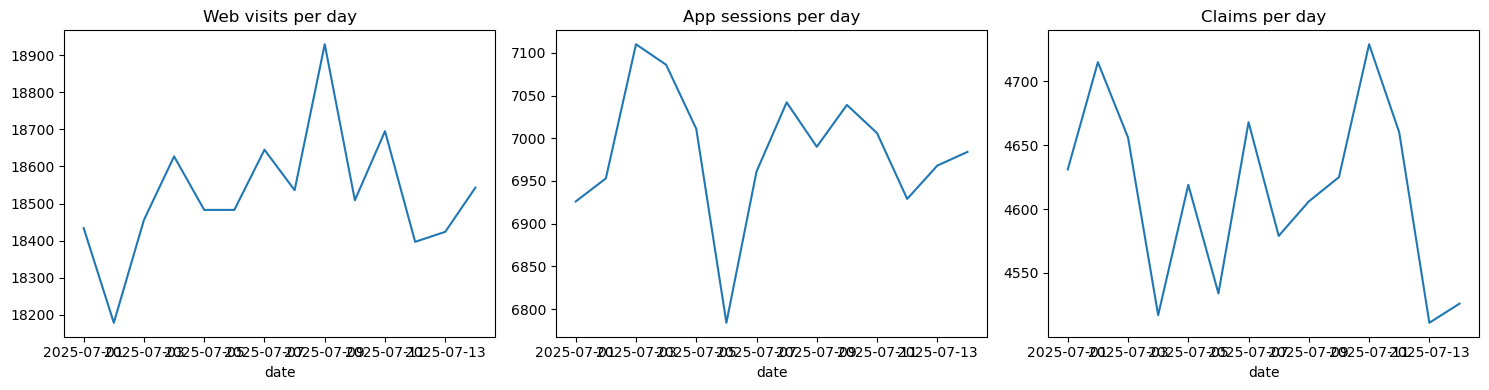

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

web["timestamp"].dt.date.value_counts().sort_index().plot(
    ax=axes[0], title="Web visits per day"
)
axes[0].set_xlabel("date")

app["timestamp"].dt.date.value_counts().sort_index().plot(
    ax=axes[1], title="App sessions per day"
)
axes[1].set_xlabel("date")

claims["diagnosis_date"].dt.date.value_counts().sort_index().plot(
    ax=axes[2], title="Claims per day"
)
axes[2].set_xlabel("date")

plt.tight_layout()
plt.show()


### 5. Web visits: domains, volume, and noise

In [25]:
web["domain"] = web["url"].fillna("").astype(str).str.extract(r"https?://([^/]+)", expand=False)

print("Top 20 domains:")
web["domain"].value_counts().head(20)


Top 20 domains:


domain
portal.site       44325
example.com       39960
world.news        39007
media.hub         34548
care.portal       25471
living.better     25438
guide.wellness    25313
health.wellco     25278
Name: count, dtype: int64

In [26]:
web["member_id"] = web["member_id"].astype("int64")
web_per_member = web.groupby("member_id")["url"].size().rename("web_visits_count")

print("Web visits per member - describe:")
web_per_member.describe()


Web visits per member - describe:


count    9975.000000
mean       25.998997
std        17.209289
min         1.000000
25%        13.000000
50%        22.000000
75%        35.000000
max       140.000000
Name: web_visits_count, dtype: float64


#### If you already use a content-based filter (health keywords) in your pipeline,
#### we can inspect how much data is removed.


In [27]:
from src.data.build_base_table import filter_web_visits


web_filtered = filter_web_visits(web)
print("Original web_visits rows:", len(web))
print("Filtered web_visits rows:", len(web_filtered))
print("Kept fraction:", (len(web_filtered) / len(web)))


Original web_visits rows: 259340
Filtered web_visits rows: 101500
Kept fraction: 0.3913781136731704


In [28]:
from src.data.build_base_table import filter_web_visits


web_filtered = filter_web_visits(web)
print("Original web_visits rows:", len(web))
print("Filtered web_visits rows:", len(web_filtered))
print("Kept fraction:", (len(web_filtered) / len(web)))


Original web_visits rows: 259340
Filtered web_visits rows: 101500
Kept fraction: 0.3913781136731704


### 6. App usage: engagement patterns


In [29]:
app["member_id"] = app["member_id"].astype("int64")
app["date"] = app["timestamp"].dt.date

sessions_per_member = app.groupby("member_id")["event_type"].size().rename("sessions_total")
active_days_per_member = app.groupby("member_id")["date"].nunique().rename("app_active_days")

eng_app = (
    pd.concat([sessions_per_member, active_days_per_member], axis=1)
    .reset_index()
)

eng_app.describe()


,member_id,sessions_total,app_active_days
count,9998.000000,9998.000000,9998.000000
mean,5000.181736,9.780856,6.967994
std,2887.082017,3.625525,2.066073
min,1.000000,1.000000,1.000000
25%,2500.250000,7.000000,6.000000
50%,4999.500000,10.000000,7.000000
75%,7500.750000,12.000000,8.000000
max,10000.000000,26.000000,14.000000


### 7. Claims: ICD code distribution and key conditions


In [30]:
claims["member_id"] = claims["member_id"].astype("int64")
claims["icd_code"] = claims["icd_code"].astype(str).str.upper()

print("Top 20 ICD codes:")
claims["icd_code"].value_counts().head(20)


Top 20 ICD codes:


icd_code
Z71.3    9145
I10      9006
E11.9    8961
H10.9    5414
B34.9    5410
A09      5387
M54.5    5385
J00      5346
R51      5277
K21.9    5245
Name: count, dtype: int64

In [31]:
def has_icd(df: pd.DataFrame, code: str, col_name: str) -> pd.Series:
    mask = df["icd_code"].eq(code.upper())
    return (
        df.loc[mask]
        .groupby("member_id")["icd_code"]
        .size()
        .gt(0)
        .astype(int)
        .rename(col_name)
    )

has_diabetes = has_icd(claims, "E11.9", "has_diabetes_E11_9")
has_htn = has_icd(claims, "I10", "has_hypertension_I10")
has_diet = has_icd(claims, "Z71.3", "has_diet_counseling_Z71_3")

clinical_flags = (
    pd.concat([has_diabetes, has_htn, has_diet], axis=1)
    .reset_index()
    .fillna(0)
)

clinical_flags.mean().round(3)


member_id                    5002.793
has_diabetes_E11_9              0.636
has_hypertension_I10            0.637
has_diet_counseling_Z71_3       0.638
dtype: float64

### 8. Member-level merge for simple EDA


In [32]:
web_counts = web.groupby("member_id")["url"].size().rename("web_visits_count")
app_counts = app.groupby("member_id")["event_type"].size().rename("app_sessions_total")

member_agg = (
    labels.set_index("member_id")
    .join(web_counts)
    .join(app_counts)
    .join(clinical_flags.set_index("member_id"), how="left")
    .reset_index()
)

member_agg[["web_visits_count", "app_sessions_total"]] = member_agg[
    ["web_visits_count", "app_sessions_total"]
].fillna(0)

member_agg.head()


,member_id,signup_date,churn,outreach,web_visits_count,app_sessions_total,has_diabetes_E11_9,has_hypertension_I10,has_diet_counseling_Z71_3
0,1,2024-04-12,0,0,3.0,6.0,1.0,1.0,1.0
1,2,2025-03-11,0,0,9.0,10.0,1.0,1.0,1.0
2,3,2024-09-27,0,0,52.0,9.0,1.0,0.0,0.0
3,4,2024-04-16,1,0,15.0,10.0,0.0,1.0,0.0
4,5,2024-03-12,0,1,11.0,10.0,1.0,1.0,1.0


### 9. Engagement vs churn and outreach


In [33]:
for col in ["web_visits_count", "app_sessions_total"]:
    member_agg[col] = member_agg[col].fillna(0)

member_agg["web_bin"] = pd.qcut(member_agg["web_visits_count"], q=4, duplicates="drop")
member_agg["app_bin"] = pd.qcut(member_agg["app_sessions_total"], q=4, duplicates="drop")

print("Churn rate by web_visits_count quartile:")
print(
    member_agg.groupby("web_bin")["churn"].mean().round(3)
)

print("\nChurn rate by app_sessions_total quartile:")
print(
    member_agg.groupby("app_bin")["churn"].mean().round(3)
)

print("\nOutreach rate by web_visits_count quartile:")
print(
    member_agg.groupby("web_bin")["outreach"].mean().round(3)
)


Churn rate by web_visits_count quartile:
web_bin
(-0.001, 13.0]    0.211
(13.0, 22.0]      0.195
(22.0, 35.0]      0.194
(35.0, 140.0]     0.208
Name: churn, dtype: float64

Churn rate by app_sessions_total quartile:
app_bin
(-0.001, 7.0]    0.242
(7.0, 10.0]      0.203
(10.0, 12.0]     0.190
(12.0, 26.0]     0.160
Name: churn, dtype: float64

Outreach rate by web_visits_count quartile:
web_bin
(-0.001, 13.0]    0.397
(13.0, 22.0]      0.395
(22.0, 35.0]      0.385
(35.0, 140.0]     0.417
Name: outreach, dtype: float64


C:\Users\ezer6\AppData\Local\Temp\ipykernel_31224\705731562.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  member_agg.groupby("web_bin")["churn"].mean().round(3)
C:\Users\ezer6\AppData\Local\Temp\ipykernel_31224\705731562.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  member_agg.groupby("app_bin")["churn"].mean().round(3)
C:\Users\ezer6\AppData\Local\Temp\ipykernel_31224\705731562.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and 

### 10. Outreach assignment patterns


In [34]:
print("Outreach rate by diabetes flag:")
print(
    member_agg.groupby("has_diabetes_E11_9")["outreach"].mean().round(3)
)

print("\nOutreach rate by hypertension flag:")
print(
    member_agg.groupby("has_hypertension_I10")["outreach"].mean().round(3)
)

print("\nChurn by outreach within diabetes=1:")
print(
    member_agg[member_agg["has_diabetes_E11_9"] == 1]
    .groupby("outreach")["churn"]
    .mean()
    .round(3)
)


Outreach rate by diabetes flag:
has_diabetes_E11_9
0.0    0.400
1.0    0.397
Name: outreach, dtype: float64

Outreach rate by hypertension flag:
has_hypertension_I10
0.0    0.398
1.0    0.397
Name: outreach, dtype: float64

Churn by outreach within diabetes=1:
outreach
0    0.197
1    0.191
Name: churn, dtype: float64


### 11. Processed base table quick look


In [35]:
train_table_path = DATA_PROCESSED / "train_table.parquet"
if train_table_path.exists():
    train_base = pd.read_parquet(train_table_path)
    print("train_table.parquet shape:", train_base.shape)
    display(train_base.head())
    print(train_base.isna().mean().sort_values(ascending=False).head(20))
else:
    print("No processed train_table.parquet found yet.")


train_table.parquet shape: (10000, 26)


,member_id,y_churn,t_outreach,signup_date,signup_days_since_min,web_total_visits,web_unique_urls,web_first_visit_ts,web_last_visit_ts,web_active_days,...,app_first_session_ts,app_last_session_ts,app_days_since_last_session,claims_total,has_diabetes_E11_9,has_hypertension_I10,has_diet_counseling_Z71_3,claims_first_diag_date,claims_last_diag_date,claims_span_days
0,1,0.0,0.0,2024-04-12,102.0,2.0,2.0,2025-07-02 22:38:22+00:00,2025-07-14 00:38:39+00:00,2.0,...,2025-07-02 19:43:17+00:00,2025-07-14 15:28:58+00:00,0.354780,9.0,1.0,1.0,1.0,2025-07-01,2025-07-14,13.0
1,2,0.0,0.0,2025-03-11,435.0,8.0,8.0,2025-07-01 00:37:35+00:00,2025-07-11 20:58:01+00:00,6.0,...,2025-07-02 07:21:31+00:00,2025-07-14 01:37:25+00:00,0.932245,9.0,1.0,1.0,1.0,2025-07-02,2025-07-13,11.0
2,3,0.0,0.0,2024-09-27,270.0,23.0,23.0,2025-07-01 07:12:25+00:00,2025-07-14 04:06:06+00:00,12.0,...,2025-07-01 18:07:50+00:00,2025-07-12 05:42:20+00:00,2.762164,4.0,1.0,0.0,0.0,2025-07-02,2025-07-14,12.0
3,4,1.0,0.0,2024-04-16,106.0,7.0,7.0,2025-07-01 21:15:15+00:00,2025-07-13 14:58:27+00:00,5.0,...,2025-07-01 10:39:28+00:00,2025-07-13 22:17:45+00:00,1.070903,5.0,0.0,1.0,0.0,2025-07-07,2025-07-13,6.0
4,5,0.0,1.0,2024-03-12,71.0,6.0,6.0,2025-07-05 21:58:24+00:00,2025-07-13 22:48:22+00:00,4.0,...,2025-07-01 08:40:53+00:00,2025-07-13 22:06:17+00:00,1.078866,7.0,1.0,1.0,1.0,2025-07-06,2025-07-14,8.0


web_first_visit_ts             0.0212
web_last_visit_ts              0.0212
relevant_url_rate              0.0212
claims_last_diag_date          0.0020
claims_first_diag_date         0.0020
has_diet_counseling_Z71_3      0.0020
has_hypertension_I10           0.0020
has_diabetes_E11_9             0.0020
app_last_session_ts            0.0002
app_first_session_ts           0.0002
member_id                      0.0000
app_sessions_per_active_day    0.0000
claims_total                   0.0000
app_days_since_last_session    0.0000
app_sessions_total             0.0000
app_active_days                0.0000
y_churn                        0.0000
web_total_visits_unfiltered    0.0000
web_days_since_last_visit      0.0000
web_active_days                0.0000
dtype: float64


In [36]:
train_table_path = DATA_PROCESSED / "train_table.parquet"
print(train_table_path)
if train_table_path.exists():
    train_base = pd.read_parquet(train_table_path)
    print("train_table.parquet shape:", train_base.shape)
    display(train_base.head())
    print(train_base.isna().mean().sort_values(ascending=False).head(20))
else:
    print("No processed train_table.parquet found yet.")


C:\Projects\Vi\data\processed\train_table.parquet
train_table.parquet shape: (10000, 26)


,member_id,y_churn,t_outreach,signup_date,signup_days_since_min,web_total_visits,web_unique_urls,web_first_visit_ts,web_last_visit_ts,web_active_days,...,app_first_session_ts,app_last_session_ts,app_days_since_last_session,claims_total,has_diabetes_E11_9,has_hypertension_I10,has_diet_counseling_Z71_3,claims_first_diag_date,claims_last_diag_date,claims_span_days
0,1,0.0,0.0,2024-04-12,102.0,2.0,2.0,2025-07-02 22:38:22+00:00,2025-07-14 00:38:39+00:00,2.0,...,2025-07-02 19:43:17+00:00,2025-07-14 15:28:58+00:00,0.354780,9.0,1.0,1.0,1.0,2025-07-01,2025-07-14,13.0
1,2,0.0,0.0,2025-03-11,435.0,8.0,8.0,2025-07-01 00:37:35+00:00,2025-07-11 20:58:01+00:00,6.0,...,2025-07-02 07:21:31+00:00,2025-07-14 01:37:25+00:00,0.932245,9.0,1.0,1.0,1.0,2025-07-02,2025-07-13,11.0
2,3,0.0,0.0,2024-09-27,270.0,23.0,23.0,2025-07-01 07:12:25+00:00,2025-07-14 04:06:06+00:00,12.0,...,2025-07-01 18:07:50+00:00,2025-07-12 05:42:20+00:00,2.762164,4.0,1.0,0.0,0.0,2025-07-02,2025-07-14,12.0
3,4,1.0,0.0,2024-04-16,106.0,7.0,7.0,2025-07-01 21:15:15+00:00,2025-07-13 14:58:27+00:00,5.0,...,2025-07-01 10:39:28+00:00,2025-07-13 22:17:45+00:00,1.070903,5.0,0.0,1.0,0.0,2025-07-07,2025-07-13,6.0
4,5,0.0,1.0,2024-03-12,71.0,6.0,6.0,2025-07-05 21:58:24+00:00,2025-07-13 22:48:22+00:00,4.0,...,2025-07-01 08:40:53+00:00,2025-07-13 22:06:17+00:00,1.078866,7.0,1.0,1.0,1.0,2025-07-06,2025-07-14,8.0


web_first_visit_ts             0.0212
web_last_visit_ts              0.0212
relevant_url_rate              0.0212
claims_last_diag_date          0.0020
claims_first_diag_date         0.0020
has_diet_counseling_Z71_3      0.0020
has_hypertension_I10           0.0020
has_diabetes_E11_9             0.0020
app_last_session_ts            0.0002
app_first_session_ts           0.0002
member_id                      0.0000
app_sessions_per_active_day    0.0000
claims_total                   0.0000
app_days_since_last_session    0.0000
app_sessions_total             0.0000
app_active_days                0.0000
y_churn                        0.0000
web_total_visits_unfiltered    0.0000
web_days_since_last_visit      0.0000
web_active_days                0.0000
dtype: float64
